# 02. Sales & Category Performance Analysis
**Deskripsi:** Analisis performa penjualan (sold) per kategori produk dan identifikasi produk terlaris.


In [4]:
# 1. Load Processed Data dari 'data/processed/tokopedia_cleaned.csv'
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../data/processed/tokopedia_cleaned.csv")
sns.set_theme(style="whitegrid")

In [5]:
# 2. Agregasi Total Sold & Product Count per Category
category_summary = df.groupby('category').agg(
    total_sold=('sold', 'sum'),
    avg_rating=('rating', 'mean'),
    total_products=('product_id', 'count')
).reset_index().sort_values(by='total_sold', ascending=False)

print("--- Ringkasan Performa Per Kategori ---")
print(category_summary)

--- Ringkasan Performa Per Kategori ---
      category  total_sold  avg_rating  total_products
3     olahraga     1855530    4.579740            7838
0   elektronik     1561262    4.757501           15897
1      fashion     1438174    4.674523            8910
2    handphone      911236    4.378422            6136
4  pertukangan      407628    4.643483            1826


C:\Users\user\AppData\Local\Temp\ipykernel_15112\2162150000.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(data=category_summary, x='category', y='total_sold', palette='Blues_r')


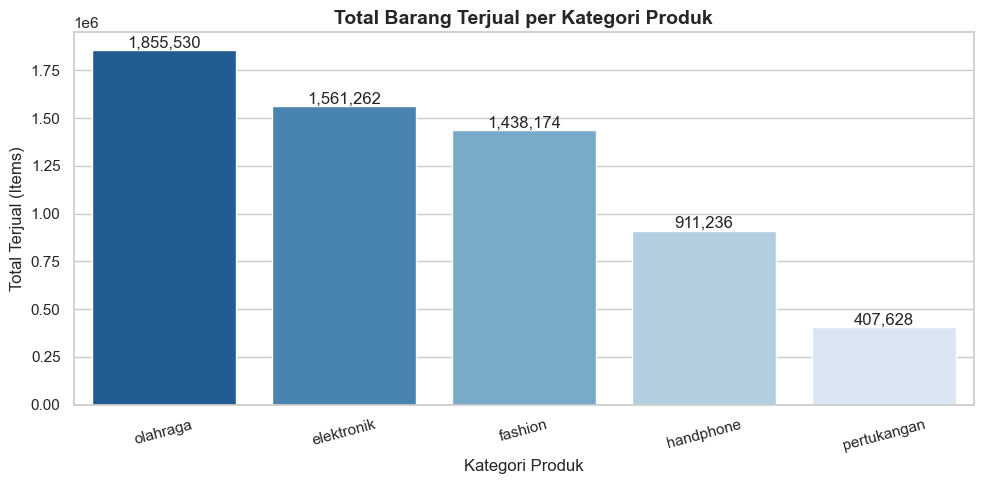

In [6]:
# 3. Distribusi Penjualan per Kategori (Bar Chart / Pie Chart)
plt.figure(figsize=(10, 5))
ax = sns.barplot(data=category_summary, x='category', y='total_sold', palette='Blues_r')
plt.title('Total Barang Terjual per Kategori Produk', fontsize=14, fontweight='bold')
plt.xlabel('Kategori Produk')
plt.ylabel('Total Terjual (Items)')
plt.xticks(rotation=15)

for p in ax.patches:
    ax.annotate(f'{int(p.get_height()):,}', 
                (p.get_x() + p.get_width() / 2., p.get_height()), 
                ha='center', va='center', xytext=(0, 5), textcoords='offset points')

plt.tight_layout()
plt.savefig("../outputs/figures/sales_by_category.png", dpi=300)
plt.show()

In [7]:
# 4. Top 10 Products Terlaris Keseluruhan & per Kategori
top_10_products = df.sort_values(by='sold', ascending=False)[['product_name', 'category', 'sold', 'rating']].head(10)
print("\n--- Top 10 Produk Terlaris ---")
print(top_10_products)


--- Top 10 Produk Terlaris ---
                                           product_name category  sold  rating
3743  Sepatu Sekolah Nike Roshe Run Full Hitam Anak ...  fashion   994       5
3906  Sepatu Sekolah Nike Roshe Run Full Hitam Anak ...  fashion   994       4
3809  Sepatu Sekolah Nike Roshe Run Full Hitam Anak ...  fashion   994       5
3808  Sepatu Sekolah Nike Roshe Run Full Hitam Anak ...  fashion   994       5
3807  Sepatu Sekolah Nike Roshe Run Full Hitam Anak ...  fashion   994       4
3806  Sepatu Sekolah Nike Roshe Run Full Hitam Anak ...  fashion   994       4
3805  Sepatu Sekolah Nike Roshe Run Full Hitam Anak ...  fashion   994       5
3804  Sepatu Sekolah Nike Roshe Run Full Hitam Anak ...  fashion   994       5
3803  Sepatu Sekolah Nike Roshe Run Full Hitam Anak ...  fashion   994       5
3907  Sepatu Sekolah Nike Roshe Run Full Hitam Anak ...  fashion   994       4


In [ ]:
# 5. Simpan Grafik ke 'outputs/figures/sales_by_category.png'
